# Washington tire market opportunity (POC)

## 1. Summary

**Question:** Where in Washington do tire-specialist retailers (independent shops and tire chains) capture more tire sales than cars on the road and dealer activity would predict, and are they gaining share faster than vehicle growth? These are candidate markets where dealerships may be losing tire business.

**Summary:** We modelled expected tire-specialist sales (WA taxable sales of tire dealers, NAICS 441320 → 441340) from registered vehicles and two dealer-activity controls (Census dealer employment as primary, dealer taxable sales as secondary), using 2017–2025. We flagged counties whose tire-specialist sales sit above expectation beyond typical model error and grew faster than registered vehicles from 2019 to 2025, and capped any county at Watch when one city drives more than half of its growth. **No county is a robust candidate:** Kittitas passes under both dealer controls but is capped at Watch because Cle Elum alone accounts for 182% of its real tire-specialist growth, and Asotin is on Watch (dealer-sales view only; Clarkston 95%). The main caveat: both signals rest on one city each, and dealer tire sales are not observable, so these are **candidates to investigate, not proof** that dealerships are losing tire business.

> Markets where tire specialists capture more than cars on the road explain and are gaining share faster than vehicle growth. Dealers may be among those losing share; confirming this needs dealer-level tire sales.


In [1]:
import pandas as pd
from IPython.display import Markdown
from wa_tire import config, plots, signals
from wa_tire.build import load_processed
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)

## 2. Data

This section shows where the numbers come from, what period they cover, and which counties were left out and why.

- **Target:** WA taxable retail sales, tire dealers (NAICS 441320 → 441340): sales captured by tire-specialist retailers (independent shops + tire chains); county × quarter; available 2005–2026Q1; 2017–2025 used because vehicle registrations start in 2017. Source: WA Dept. of Revenue, Taxable Retail Sales (local) builder. Cities and unincorporated areas are summed to counties; transit-area (PTBA) and empty `xx99` codes are dropped (`reports/location_codes.md`).
- **Dealer sales (secondary dealer measure):** same source, new-car dealers (NAICS 441110).
- **Dealer employment (primary dealer measure):** Census County Business Patterns, NAICS 441110, mid-March employment, 2017–2023. Small counties are not published.
- **Demand:** WA Dept. of Licensing registration transactions, Passenger Vehicle + Truck, by owner's county, 2017–2025 (data.wa.gov `hmzg-s6q4`).
- **Prices:** BLS CPI-U Tires (`CUUR0000SETC01`) for tire-specialist sales and New vehicles (`CUUR0000SETA01`) for dealer sales; constant 2025 dollars.
- **Exclusions:** a county-quarter counts as hidden when suppressed cells could hold more than 25% of tire-specialist taxpayers. Counties hidden in more than 25% of quarters are excluded from all views. Each view also drops counties that lack its dealer measure in any model year.

In [2]:
coverage = load_processed("coverage")
coverage.loc[coverage["excluded"], ["county", "hidden_quarter_share", "reason"]]

,county,hidden_quarter_share,reason
6,Columbia,0.467,tire data hidden in 47% of quarters
8,Douglas,0.356,tire data hidden in 36% of quarters
11,Garfield,0.622,tire data hidden in 62% of quarters; a model year with no disclosed tire-specialist sales
13,Grays Harbor,0.333,tire data hidden in 33% of quarters
21,Lincoln,0.778,tire data hidden in 78% of quarters
24,Pacific,0.533,tire data hidden in 53% of quarters
25,Pend Oreille,0.556,tire data hidden in 56% of quarters
29,Skamania,0.733,tire data hidden in 73% of quarters
34,Wahkiakum,0.511,tire data hidden in 51% of quarters
37,Whitman,0.911,tire data hidden in 91% of quarters


In [3]:
load_processed("view_summary")

,view,measure,model_years,test_years,counties,dropped_no_dealer_data,missing_growth_data_2019_2025,top_candidates
0,cbp_emp,New-car dealer employment (CBP),2017-2023,2022-2023,20,"Adams, Asotin, Ferry, Island, Jefferson, Klickitat, Mason, San Juan, Stevens",none,Kittitas
1,sales,New-car dealer real taxable sales (DOR),2017-2025,2022-2025,29,NaN,none,"Asotin, Kittitas"


## 3. Exploration

This chart shows statewide real taxable sales for tire specialists and new-car dealers, each indexed to its 2019 average.

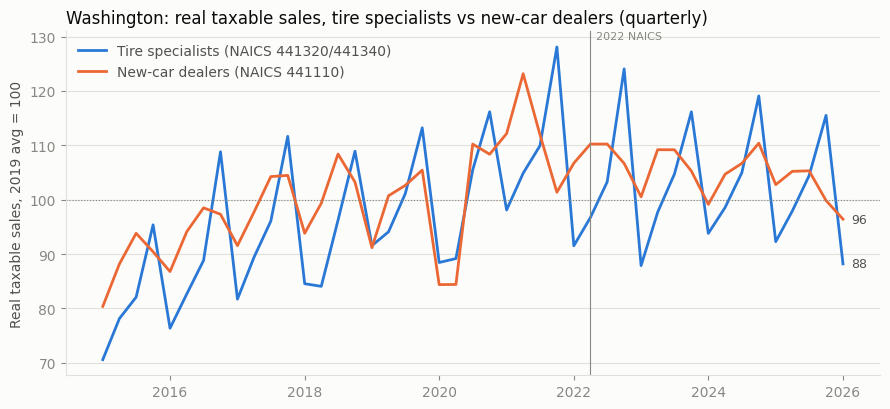

In [4]:
cq = load_processed("county_quarter")
plots.statewide_index(cq);

## 4. Model

This section shows how expected tire-specialist sales are estimated for each county.

- **Baseline:** real tire-specialist sales per registered vehicle × county vehicles.
- **Model:** OLS of log real tire-specialist sales on log vehicles and log dealer activity, with year effects (standard errors clustered by county).
- **Dealer activity** is CBP new-car dealer employment (primary view) or DOR real new-car-dealer sales (secondary view).
- **Split:** train 2017–2021; test 2022–2023 (CBP view) or 2022–2025 (sales view).
- Dealer activity appears **only in this level model**. The growth signal compares tire-specialist sales with registered vehicles.
- **Calibration:** both methods are scaled each year to the actual total of the counties in the view, so the test measures how well each method *allocates* sales across counties.

In [5]:
load_processed("coefficients_cbp_emp")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.652,0.163,0.000,100,0.955
1,log_dealer,0.148,0.142,0.298,100,0.955


In [6]:
load_processed("coefficients_sales")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.398,0.213,0.062,145,0.821
1,log_dealer,0.348,0.165,0.035,145,0.821


## 5. Evaluation

These tables compare baseline and model errors on the test years for each view (MAPE = mean absolute percentage error).

In [7]:
load_processed("evaluation_cbp_emp")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.207,0.237,40,2022-2023
1,model,0.137,0.132,40,2022-2023


In [8]:
load_processed("evaluation_sales")

,method,MAPE,mean_abs_log_error,n_county_years,years
0,baseline,0.774,0.358,116,2022-2025
1,model,0.435,0.305,116,2022-2025


## 6. Results

This section ranks counties on both signals, shows which counties are flagged under each dealer measure, and lists hypotheses other than dealer loss.

- **Residual flag:** actual above the out-of-sample expectation in every recent test year, *and* the mean recent log residual is more than 1× the model's typical error (median absolute test log error). `residual_z` is that ratio.
- **Growth flag:** top quartile on the relative growth gap, with the gap > 0 and real tire-specialist growth > 0. The relative gap is (county − state tire-specialist growth) − (county − state registered-vehicle growth), 2019→2025. It ranks counties exactly like the raw gap; only the zero line moves. Dealer activity is used only in the level model.
- **Top candidate:** both flags.

### Candidate tiers

**Robust** = top candidate under both dealer measures and no single city above 50% of the county's real tire-specialist growth 2019→2025. **Watch** = top candidate under one measure only (including counties the CBP view cannot assess), or capped because one city accounts for more than 50% of the growth. The cap is not applied when that city's data is hidden in 2019 or 2025.

In [9]:
load_processed("candidate_tiers")

,county,tier,reason,top_jurisdiction,top_jurisdiction_share_of_growth,top_jurisdiction_hidden
0,Kittitas,Watch,Flagged under both dealer measures. Capped at Watch: Cle Elum accounts for 182% of real tire-specialist sales growth (more than all of it; the rest of the county fell).,Cle Elum,1.822,False
1,Asotin,Watch,Flagged under dealer sales only; not assessable under CBP dealer employment (no published data). Also concentrated: Clarkston accounts for 95% of real tire-specialist sales growth.,Clarkston,0.954,False


### City-level breakdown (flagged counties)

This table shows each flagged county's real tire-specialist sales by city, 2019 vs 2025, with the number of hidden quarters per city.

In [10]:
load_processed("city_breakdown")

,county,location,real_base,real_end,hidden_q_base,hidden_q_end,real_change,share_of_county_change,period
0,Asotin,Clarkston,"4,451,778.200","5,152,128.803",0,0,"700,350.603",0.954,2019-2025
1,Asotin,Asotin City,0.000,"29,784.595",4,1,"29,784.595",0.041,2019-2025
2,Asotin,Unincorporated Asotin County,"182,843.446","187,162.787",0,0,"4,319.341",0.006,2019-2025
3,Kittitas,Cle Elum,"54,161.400","3,991,652.930",0,0,"3,937,491.530",1.822,2019-2025
4,Kittitas,Kittitas City,0.000,"33,706.873",2,1,"33,706.873",0.016,2019-2025
5,Kittitas,Roslyn,"5,933.530","9,524.305",2,3,"3,590.775",0.002,2019-2025
6,Kittitas,South Cle Elum,"3,144.332",0.000,1,3,"-3,144.332",-0.001,2019-2025
7,Kittitas,Unincorporated Kittitas County,"911,016.761","634,259.969",0,0,"-276,756.792",-0.128,2019-2025
8,Kittitas,Ellensburg,"14,810,531.478","13,277,300.181",0,0,"-1,533,231.297",-0.709,2019-2025


*How the signal definition changed:* earlier versions compared tire growth with dealer activity, which flagged Grant (Robust) and Kittitas and Jefferson (Watch). Switching the comparison to registered vehicles and adding the concentration cap gives the tiers above. The residual flag never changed. See `reports/signal_definition_change.md`.

### Primary view: CBP dealer employment

In [11]:
ranked = load_processed("signals_cbp_emp")
ranked[["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "vehicle_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,vehicle_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Kittitas,2,2,0.125,1.064,0.128,-0.004,0.109,True,True,True
1,Grant,2,2,0.300,2.366,0.085,0.049,0.013,True,False,False
2,Cowlitz,2,2,0.049,0.430,0.034,-0.038,0.049,False,False,False
3,Pierce,2,2,0.020,0.175,0.038,-0.040,0.055,False,True,False
4,Skagit,0,2,-0.098,-0.929,0.143,-0.040,0.160,False,True,False
5,Okanogan,2,2,0.051,0.447,0.009,0.008,-0.022,False,False,False
6,Yakima,2,2,0.036,0.317,0.071,0.023,0.024,False,False,False
7,Franklin,2,2,0.278,2.211,0.041,0.062,-0.045,True,False,False
8,Spokane,2,2,0.268,2.141,0.023,0.038,-0.038,True,False,False
9,Kitsap,0,2,-0.263,-2.756,0.170,-0.032,0.179,False,True,False


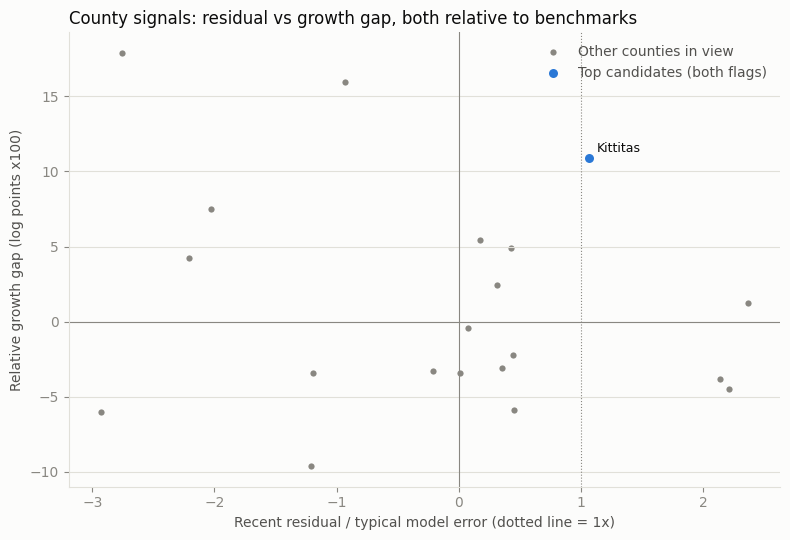

In [12]:
plots.signal_scatter(ranked, config.RESIDUAL_Z_MIN);

### Secondary view: dealer sales

In [13]:
ranked_sales = load_processed("signals_sales")
ranked_sales.loc[ranked_sales["residual_flag"] | ranked_sales["growth_flag"], ["county", "test_years_above", "test_years", "residual_pct", "residual_z", "tire_growth_log", "vehicle_growth_log", "relative_gap_log", "residual_flag", "growth_flag", "top_candidate"]]

,county,test_years_above,test_years,residual_pct,residual_z,tire_growth_log,vehicle_growth_log,relative_gap_log,residual_flag,growth_flag,top_candidate
0,Asotin,4,4,1.214,4.518,0.147,-0.048,0.169,True,True,True
1,Kittitas,4,4,0.497,2.295,0.128,-0.004,0.107,True,True,True
2,Island,2,4,0.080,0.438,0.050,-0.056,0.080,False,True,False
3,Jefferson,4,4,0.673,2.925,0.026,-0.038,0.038,True,False,False
4,Mason,2,4,-0.003,-0.016,0.151,-0.021,0.147,False,True,False
5,Grant,4,4,0.495,2.286,0.085,0.049,0.010,True,False,False
7,Skagit,0,4,-0.115,-0.697,0.143,-0.040,0.157,False,True,False
8,Okanogan,4,4,0.218,1.121,0.009,0.008,-0.025,True,False,False
10,Adams,4,4,1.992,6.232,-0.052,0.058,-0.136,True,False,False
12,Kitsap,0,4,-0.264,-1.744,0.170,-0.032,0.176,False,True,False


### Do candidates change with the dealer measure?

In [14]:
comparison = load_processed("candidates_by_view")
comparison[comparison.filter(like="top_candidate").eq(True).any(axis=1)]

,county,residual_flag_cbp_emp,growth_flag_cbp_emp,top_candidate_cbp_emp,residual_flag_sales,growth_flag_sales,top_candidate_sales
0,Kittitas,True,True,True,True,True,True
20,Asotin,NaN,NaN,NaN,True,True,True


### Plausible explanations other than dealer loss (hypotheses, untested)

Each flagged county could show a high or fast-growing tire-specialist signal for reasons that have nothing to do with dealerships losing tire business. These are **hypotheses** to check, not findings.

| County | Tier | Hypotheses other than dealer loss |
|---|---|---|
| Kittitas | Watch (capped) | **One city drives it:** Cle Elum accounts for 182% of real growth (the rest of the county fell), where tire-specialist sales jumped about 40-fold from 2024Q2 with the same number of taxpayers. That points to a new or expanded shop, a business reclassified into 441340, or a change in reporting location. Cle Elum sits at the east foot of Snoqualmie Pass on I-90, so through-traffic (winter tires, chains, roadside replacements) is plausible demand. Central Washington University students' cars may be registered elsewhere. The CBP residual is only 1.06× typical error. |
| Asotin | Watch | **Cross-border market:** 95% of the real growth is Clarkston, which forms one metro with Lewiston, Idaho. Clarkston tire specialists may serve Idaho residents, while Asotin residents may buy cars from Lewiston dealers. That would make local dealer activity (about $1M a year in disclosed sales, often hidden) understate the market and inflate the residual. Not assessable with CBP data. |


In [15]:
flagged = signals.flagged_counties(comparison, ["cbp_emp", "sales"])
flagged

['Kittitas', 'Asotin']

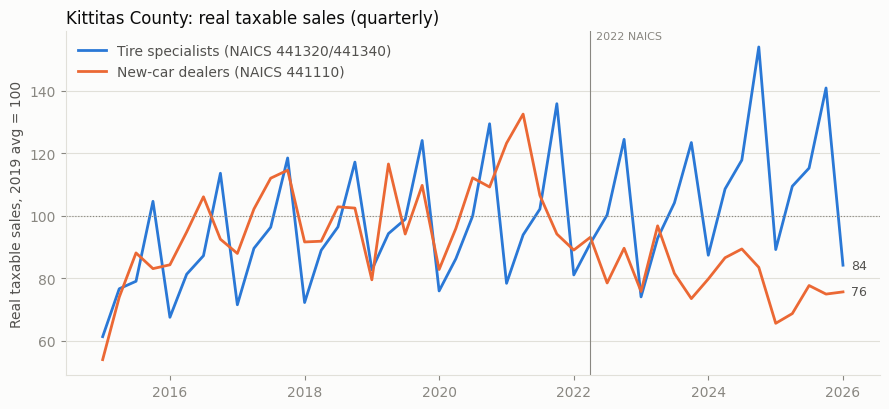

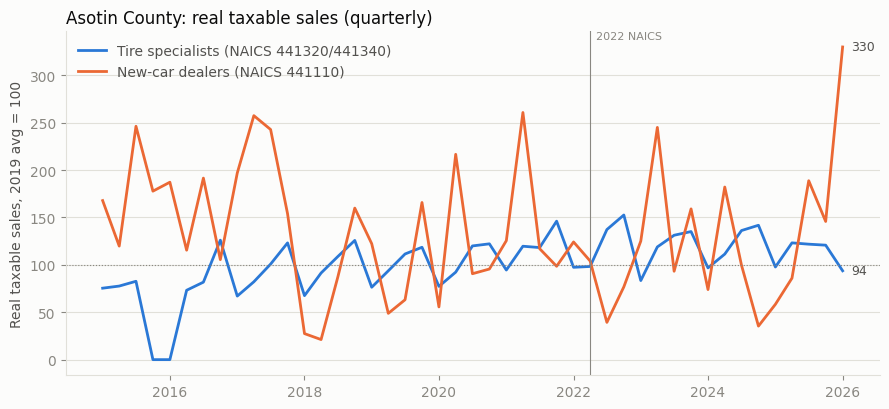

In [16]:
for county in flagged:
    plots.county_index(cq, county)

### Other findings

In the CBP model, dealer employment adds little once vehicles are included: its coefficient is 0.15 (p = 0.30), against 0.65 for vehicles (p < 0.001). In this data, tire-specialist sales track cars on the road more than dealer presence. This is an observation from 20 Washington counties over 2017–2023, not a general conclusion.

In [17]:
load_processed("coefficients_cbp_emp")

,term,coef,std_err (cluster by county),p_value,n_obs,r_squared
0,log_vehicles,0.652,0.163,0.000,100,0.955
1,log_dealer,0.148,0.142,0.298,100,0.955


## 7. Caveats

This section lists what limits these results and what each limitation could change. It is the content of `CAVEATS.md`.

In [18]:
Markdown((config.ROOT / "CAVEATS.md").read_text())

# Caveats

The results are **candidate markets, not proof** that dealerships are losing tire business. The target is sales captured by **tire-specialist retailers (independent shops and tire chains)**, shortened to "tire specialists" below. Each caveat says what it could change.

| # | Caveat | What it could change |
|---|---|---|
| 1 | **One state.** Washington only, because it is the state found that publishes six-digit tire-dealer (NAICS 441320/441340) sales by county (see `reports/state_sales_check.md`). | Nothing here transfers to other states without equivalent data. Washington's tax rules (no income tax, destination sourcing) may make its pattern atypical. |
| 2 | **39 counties, fewer modelled.** Ten small counties are excluded for tire-specialist data suppression (`exclusions.csv`), leaving 29. The primary CBP view also drops 9 counties where CBP does not publish new-car dealer employment in every year 2017–2023: Adams, Asotin, Ferry, Island, Jefferson, Klickitat, Mason, San Juan, Stevens. That leaves **20 counties**. | The regression is small-sample (100 county-years in the CBP view). Rankings and flags move when counties are added or dropped. Asotin, a Watch candidate, cannot be assessed in the CBP view at all. |
| 3 | **The target includes tire chains, not only independent shops.** The tire-dealer category (NAICS 441320 → 441340) covers every business whose main activity is selling tires. That includes large tire chains such as Les Schwab and Discount Tire as well as independent shops. | A tire-specialist signal can come from a chain opening or growing a store, not from independents. The two cannot be separated in the data. |
| 4 | **Big-box stores, auto-repair chains and online sellers are not in the target.** Warehouse clubs and supercenters (e.g. Costco, Walmart; NAICS 455), general auto-repair chains (NAICS 8111) and online or remote tire sellers all sell tires but are classified elsewhere. | Where those channels are strong, tire specialists look under-represented (negative residual) even though demand is being met. The analysis cannot see where any customer's tire purchase actually goes. |
| 5 | **Dealer tire sales are not observable.** New-car dealers (NAICS 441110) report one taxable-sales total covering vehicles, parts, service and tires, so **dealer tire share cannot be measured**. Dealer sales mostly reflect new-car sales, which fell nationally after 2019 (pandemic and semiconductor-shortage supply limits). Dealer activity (CBP employment primary, dealer sales secondary) is therefore used **only in the level model**, as a control for local dealer presence. | When tire specialists gain share faster than vehicle growth, **the share may come from dealers, big-box stores or online sellers**. Or no one may have lost it, if total tire spending per vehicle rose. The signal does not show that dealers lost tire business. |
| 6 | **Taxable retail sales only.** DOR reports sales subject to local retail sales tax. Tax-exempt sales are excluded: sales for resale, to exempt buyers (some government, farm and tribal purchases) and out-of-state deliveries. | Counties where tire specialists sell heavily to exempt buyers (fleets, farms, resellers) look smaller than they are, which biases their residual down. |
| 7 | **Hidden ("D") cells.** Cells with fewer than 3 taxpayers are suppressed. County totals are sums of *disclosed* cells, so they are lower bounds. Each hidden cell holds 1–2 taxpayers. | Counties with many small towns understate their sales. A change in suppression over time (a town crossing 3 shops) can create artificial growth. Hidden counts per county-quarter are in `county_quarter.csv` (`hidden_cells`, `hidden_share_ub`). |
| 8 | **Cars on the road are estimated from registrations.** These are DOL registration *transactions* for Passenger Vehicle + Truck by owner's county and calendar year. Annual renewal makes this approximate the fleet, but multi-transaction vehicles and fleet registrations add noise. DOL data start January 2017, so **modelling runs from 2017**, although tire-specialist sales are available from 2005 (train 2017–2021; test 2022–2025 in the dealer-sales view, 2022–2023 in the CBP view). All 39 counties have registrations for every year 2017–2025, so no county is missing 2019 or 2025 vehicle data. Missing counties would be reported, not imputed. | Vehicle-mix differences (trucks vs cars, studded-tire use in the east) are not in the model. |
| 9 | **The growth gap assumes stable tire spending per vehicle.** The gap is real tire-specialist log growth minus registered-vehicle log growth, 2019→2025. It reads as a share gain only if tire spending per vehicle is roughly stable across counties over time. | Tire spending per vehicle can rise for other reasons: larger or pricier tires, faster EV tire wear, more miles driven, or fleet growth not in Passenger/Truck registrations. If these differ by county, the gap mixes them with share shifts. |
| 10 | **Growth gap mechanics.** Each county's tire-specialist and vehicle growth is measured net of the trend across the counties in the view, and real tire-specialist growth must be positive. Subtracting the trend shifts every county by the same constant, so the **ranking is identical to the raw gap**; only the zero line moves. The top-quartile cut depends on the view's county set (top 5 of 20 under CBP, top 8 of 29 under dealer sales). | Flags depend on the view's county set as well as on each county's own data. Grant is outside the top quartile because its tire-specialist growth (+9%) is close to its vehicle growth (+5%). |
| 11 | **One city can drive a county; capped at Watch.** `city_breakdown.csv` gives each flagged county's real tire-specialist sales by city, 2019 vs 2025, with hidden quarters. If one city accounts for more than 50% of the county's real growth, the county is capped at Watch, unless that city's data is hidden in 2019 or 2025, in which case the cap is not applied and the reason says so. Kittitas: **Cle Elum accounts for 182%** of real growth, because Ellensburg (−10%) and the unincorporated area fell. Cle Elum's sales jumped from about $20k to about $900k a quarter starting 2024Q2, with the same 5–8 taxpayers. Asotin: **Clarkston 95%**. Both top cities are fully disclosed. | The Kittitas signal probably reflects one business opening, expanding, being reclassified into 441340 or changing where it reports sales. Shares use disclosed cells only; hidden cells in small towns (at most 2 taxpayers per hidden quarter) could shift the shares slightly. The 50% threshold is a convention. Confirming either county starts with identifying the business behind the change. |
| 12 | **Residuals have other explanations.** A positive residual can reflect cross-county shopping (a regional hub drawing rural buyers), fleet and commercial buyers, a different vehicle mix, or where a multi-location business reports its sales. | High-residual counties are often regional retail centres. A residual is a reason to look, not evidence of dealer loss. |
| 13 | **Inflation adjustment uses national CPIs.** Tire-specialist sales use the BLS CPI-U *Tires* index (`CUUR0000SETC01`); new-car-dealer sales use *New vehicles* (`CUUR0000SETA01`). Both are U.S. city averages; there is no Washington-specific index. **October 2025 is missing** for tires (BLS: lapse in appropriations), so 2025Q4 averages November and December. | Washington price trends may differ from national ones. Levels across counties are unaffected (one deflator per year). Real growth rates shift if Washington tire prices moved differently. |
| 14 | **2022 NAICS switch.** Tire dealers moved from 441320 to 441340 in 2022Q2, and the two codes are combined into one series. The switch is checked in `naics_transition_check.csv`; no level jump was found. | If some businesses were reclassified into or out of the category at the switch, the series has a level shift that would show up as growth. |
| 15 | **Evaluation is cross-sectional.** Baseline and model are both calibrated each year to the actual total of the counties in the view, because year effects for unseen test years cannot be estimated. The metrics measure how well each method *allocates* sales across counties, not how well it forecasts the state level. | A model that wins here can still forecast statewide trends badly. The signals do not use statewide forecasts. |
| 16 | **Residual signals are out of sample and scaled by model error.** Residuals come from the model trained on 2017–2021 and predicted on the test years. A county is flagged only if actual sales were above expected in *every* recent test year **and** the mean recent log residual exceeds 1× the model's typical error (the median absolute test log error over all county-years). | The threshold is a convention, not a significance test. The typical error itself is estimated from only 40 (CBP) or 116 (sales) county-years. |
| 17 | **CBP view is short and noisy.** CBP is released with a lag: 2023 is the latest year, and the 2024 endpoint returns 404. In the CBP view, the level model's test years are 2022–2023 only, so "all recent years" means 2 years. CBP counts mid-March employment at establishment location and applies noise infusion. In the CBP model, the dealer-employment coefficient is small and not significant (0.15, p = 0.30); vehicles do most of the work. | "Above expected in all recent years" is a weak filter with 2 years. Kittitas's CBP residual is 1.06× typical error, just over the 1× threshold. A re-run with CBP 2024 could move it either way. |
| 18 | **Thurston total gap.** The sum of Thurston's jurisdictions is 0.9% below DOR's own county total for NAICS 441 (2025Q4), unexplained (see `reports/location_codes.md`). | This is negligible for ranking. It suggests some sales may be assigned only at county level. |
| 19 | **Explanations other than dealer loss in the notebook are hypotheses.** They are plausible alternatives, not tested. | Any of them could account for a county's signal without any dealer losing tire business. |
| 20 | **Results are candidates, not proof.** Confirming that dealers are among those losing share needs dealer-level tire sales. | Confirming any county needs company data (dealer service and tire revenue, customer addresses) or field checks. |


## 8. With company data

This section describes how the county screen would become a list of specific dealerships. With a company's own data, each dealership's tire and service revenue, which public data cannot separate from car sales, and its customer addresses would replace the county-level proxies used here. Comparing each dealer's tire revenue per vehicle sold or serviced against peers, and against tire-specialist sales in its market area, would show which dealerships are under-capturing tire demand and turn the county signals into a ranked, dealer-level target list.
